<a href="https://colab.research.google.com/github/asiddiqha/genai-hands-on/blob/main/llm_apis_prompting_transformers_free_local.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLM APIs, Prompting and How Transformers Work

My notebook for the first part of my AI engineering coursework: calling a local open-source LLM, prompt engineering, a minimal RAG loop with FAISS, evaluating answers, and what actually happens inside GPT-2 and a Vision Transformer.

**What I cover**
1. AI engineering vs ML engineering, and the layers of an AI application
2. Calling a local open-source model (TinyLlama)
3. Prompt engineering: zero-shot, few-shot, chain of thought
4. A minimal RAG loop: local embeddings, FAISS, grounded answers
5. Evaluating answers: local-model-as-judge for faithfulness
6. Inside GPT-2: tokens, embeddings, self-attention, masking, multi-head, the decoder block
7. Positional encoding: learned, sinusoidal, RoPE
8. Decoding: greedy search, step by step
9. From base model to assistant: pretraining, SFT, RLHF
10. Vision Transformer: images as sequences of patches

**Runs on:** Google Colab. Sections 2–5 now use local Hugging Face models and need no API key. First run downloads model weights; a GPU is recommended for speed.

## 2. Calling an LLM

An LLM chat call is a list of **messages** with roles:
- `system`: sets behaviour ("You are a translator from English to Tamil").
- `user`: the actual request.
- `assistant`: earlier model replies, when I pass conversation history.

Key parameters: `temperature` (0 = most deterministic, higher = more varied), `max_tokens` (caps output length and cost).

In [1]:
# Install libraries. No OpenAI API key or paid API is used in this version.
!pip install -q faiss-cpu transformers accelerate sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 69.5 MB/s eta 0:00:00


In [2]:
# No API key setup is needed: this notebook uses local Hugging Face models.
import json
import numpy as np
import torch

In [3]:
from transformers import pipeline

# Download and run the model locally. First run may take a few minutes.
generator = pipeline(
    "text-generation",
    model="TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    device_map="auto",
)

messages = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "Explain machine learning in one sentence."},
]

output = generator(messages, max_new_tokens=100, do_sample=True, temperature=0.7)
print(output[0]["generated_text"][-1]["content"])

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Machine learning is a field that uses algorithms and data science to learn from large datasets and improve performance in various applications. Its one-sentence summary is "using data to learn from it and improve performance".


`TinyLlama-1.1B-Chat` runs inside Colab, so no data leaves my machine and there's no per-token bill. The trade-off is quality and the compute I have to provide myself.

| | Hosted API (OpenAI, Anthropic) | Open-source (Llama, Mistral, TinyLlama) |
|---|---|---|
| Quality | Strongest models | Smaller models are weaker |
| Cost | Pay per token | Pay for my own GPU |
| Data privacy | Text goes to the provider | Stays on my infrastructure |
| Control | Limited (no weights) | Full: fine-tune, quantize, self-host |

In [4]:
messages = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "Explain machine learning in one sentence."},
]

output = generator(messages, max_new_tokens=100, do_sample=True, temperature=0.7)
print(output[0]["generated_text"][-1]["content"])

[transformers] Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Machine learning is a branch of artificial intelligence that enables computers to learn and improve from data. It involves training algorithms to identify patterns and make predictions based on historical data.


In my runs TinyLlama ignored "one sentence" and wrote two or three. Small models follow instructions less reliably, which is exactly what instruction tuning is meant to fix.

## 3. Prompt engineering

I use one helper for every call so I can compare prompts fairly.

In [5]:
def get_response(messages, model=None, temperature=0.0, max_tokens=500):
    """Generate a response using the local TinyLlama model; no hosted API call."""
    # Transformers' chat pipeline applies the model's chat template to role/content messages.
    output = generator(
        messages,
        max_new_tokens=max_tokens,
        do_sample=(temperature > 0),
        temperature=max(temperature, 0.01),
        return_full_text=True,
    )
    generated = output[0]["generated_text"]
    # Chat pipelines return a list of messages; plain text pipelines return a string.
    if isinstance(generated, list):
        return generated[-1]["content"]
    return generated

### Zero-shot: instructions only

In [6]:
zero_shot_prompt = """
Classify the sentiment of this review as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "The battery life is incredible but the camera quality disappointed me."

Sentiment:
"""

print(get_response([{"role": "user", "content": zero_shot_prompt}]))

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Sentiment: POSITIVE

Based on the review, the sentiment is POSITIVE. The reviewer is expressing positive feelings about the battery life and camera quality, which are both considered positive aspects of the product.


### Few-shot: show examples first (in-context learning)

In [7]:
few_shot_prompt = """
Classify the sentiment of reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "Absolutely love this product! Best purchase ever."
Sentiment: POSITIVE

Review: "Terrible experience. Broke after one day."
Sentiment: NEGATIVE

Review: "It works as expected. Nothing special."
Sentiment: NEUTRAL

Review: "The battery life is incredible but the camera quality disappointed me."
Sentiment:
"""

print(get_response([{"role": "user", "content": few_shot_prompt}]))

[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


To classify the sentiment of reviews as POSITIVE, NEGATIVE, or NEUTRAL, we can use sentiment analysis tools that provide sentiment scores for each review. Here are some popular sentiment analysis tools:

1. Google Trends: This tool provides sentiment scores for search terms and can be used to identify trends in sentiment over time.

2. TextBlob: This Python library provides sentiment analysis using Natural Language Toolkit (NLTK). It can be used to analyze text and identify positive, negative, and neutral sentiment.

3. IBM Watson Studio: This tool provides sentiment analysis using IBM's Natural Language Understanding (NLU) service. It can be used to analyze text and identify positive, negative, and neutral sentiment.

4. Microsoft Azure Cognitive Services: This service provides sentiment analysis using Azure's Natural Language Understanding (NLU) service. It can be used to analyze text and identify positive, negative, and neutral sentiment.

5. Amazon Comprehend: This service provides

**What I observed across two runs:** zero-shot answered `NEUTRAL` once and, the second time, "MIXED ... leans NEGATIVE", which breaks my label set. Few-shot returned `Sentiment: NEUTRAL` both times. Examples fix the **output format**, not just the answer, and that matters when another program parses the output.

### Chain of thought: ask for step-by-step reasoning

In [8]:
cot_prompt = """
Solve this problem step by step.

Problem: A store sells apples for $2 each. If you buy 5 or more, you get 20% off
the total. How much would 7 apples cost?

Think through this step by step:
"""

print(get_response([{"role": "user", "content": cot_prompt}]))

[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


1. Step 1: Identify the problem
The store sells apples for $2 each.

2. Step 2: Identify the situation
The store wants to offer a discount to customers who buy 5 or more apples.

3. Step 3: Identify the problem statement
The store wants to offer a discount of 20% to customers who buy 5 or more apples.

4. Step 4: Identify the solution
To offer a discount of 20% to customers who buy 5 or more apples, the store can:

a. Offer a discount of 20% on the total price of the apples, which is $20.

b. Offer a discount of 20% on the price of each apple, which is $1.

5. Step 5: Identify the steps to achieve the solution
To offer a discount of 20% on the total price of the apples, the store can:

a. Offer a discount of 20% on the total price of the apples, which is $20.

b. Offer a discount of 20% on each apple, which is $1.

6. Step 6: Identify the consequences of not solving the problem
If the store does not offer a discount to customers who buy 5 or more apples, it may lose customers who prefe

Both runs reached $11.20 by laying out each step (7 × $2 = $14, discount $2.80). Chain of thought helps on multi-step arithmetic and logic; for simple classification it only adds tokens and cost.

| Technique | Use when | Cost |
|---|---|---|
| Zero-shot | Simple, well-known tasks | Lowest |
| Few-shot | Output format must be exact, or the task is unusual | More input tokens |
| Chain of thought | Multi-step reasoning, maths | More output tokens |

## 4. A minimal RAG loop with FAISS

LLMs only know their training data. For a legal team with 1,000 internal documents, the model has never seen them, so we **retrieve** relevant chunks and pass them in the prompt.

```
Offline: documents → local sentence embeddings (all-MiniLM-L6-v2, 384-d) → FAISS index
Online:  question → local embedding → FAISS top-k → prompt with context → local-model answer
```

No API key is required. Embeddings and generation run locally in the notebook runtime.

In [9]:
import faiss
from sentence_transformers import SentenceTransformer

documents = [
    "Python was created by Guido van Rossum and released in 1991.",
    "FAISS is a library for efficient similarity search developed by Facebook AI.",
    "RAG combines retrieval with generation to ground LLM responses in facts.",
    "Vector databases store embeddings for fast nearest-neighbor search.",
    "The text-embedding-3-small model from OpenAI produces 1536-dimensional vectors.",
]

# Local, open model; it produces 384-dimensional sentence embeddings.
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def get_embeddings(texts):
    return embedding_model.encode(
        texts,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype("float32")

doc_embeddings = get_embeddings(documents)
print("Embeddings shape:", doc_embeddings.shape)  # (5, 384)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings shape: (5, 384)


In [10]:
# Embeddings are normalized, so inner product is cosine similarity.
index = faiss.IndexFlatIP(doc_embeddings.shape[1])
index.add(doc_embeddings)

def retrieve(query, k=2):
    similarities, ids = index.search(get_embeddings([query]), k)
    return [(documents[i], round(float(score), 3)) for i, score in zip(ids[0], similarities[0])]

for doc, score in retrieve("Who created Python?"):
    print(f"{score:>6}  {doc}")

 0.775  Python was created by Guido van Rossum and released in 1991.
 0.118  FAISS is a library for efficient similarity search developed by Facebook AI.


The retrieved results depend on the local embedding model. **Top-k always returns k results**, even if one is irrelevant. For production, consider a distance threshold or reranker.

FAISS options:
- `IndexFlatL2` / `IndexFlatIP`: exact search.
- With normalized embeddings, `IndexFlatIP` gives cosine-similarity rankings.
- `IndexHNSWFlat` / `IndexIVFFlat`: approximate search for larger collections.

In [11]:
def generate_answer(query, context):
    context_str = "\n".join(context)
    return get_response([
        {"role": "system", "content": "Answer based only on the provided context. "
                                      "If the context doesn't contain the answer, say so."},
        {"role": "user", "content": f"Context:\n{context_str}\n\nQuestion: {query}"},
    ])

for query in ["Who created Python?", "Who created machine learning?"]:
    context = [doc for doc, _ in retrieve(query, k=2)]
    print(f"Q: {query}\nA: {generate_answer(query, context)}\n")

[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: Who created Python?
A: The context does not contain the answer to the question. The provided context only mentions that Python was created by Guido van Rossum and released in 1991.

Q: Who created machine learning?
A: The context does not contain information about who created machine learning. The question asks who created machine learning, and the answer is "Guido van Rossum and Facebook AI."



The second question isn't covered by my documents, and the model says so instead of using its own knowledge. That's the grounding rule in the system prompt doing its job.

## 5. Evaluating answers

Ways to evaluate LLM output:
- **Benchmarks** (MMLU): general model capability.
- **Reference metrics** (ROUGE, BLEU): overlap with a reference answer; weak for free-form text.
- **LLM-as-judge**: a second model grades an answer against a rubric.

Here the judge uses the same local TinyLlama model, so it costs no API credits. Its JSON formatting and judgments may be less reliable than a stronger hosted model; inspect results rather than treating the score as ground truth.

In [12]:
import json
import re

def judge_faithfulness(question, context, answer):
    """Use the local model to estimate how well claims are supported by retrieved context."""
    prompt = f"""You are grading a RAG system.
Context:
{chr(10).join(context)}

Question: {question}
Answer: {answer}

List each factual claim in the answer and mark it supported or unsupported by the context.
Return a JSON object with this schema:
{{"claims": [{{"claim": "claim text", "supported": true}}], "faithfulness": 0.0}}
Faithfulness is supported claims divided by total claims, from 0 to 1. If there are no factual claims, use 1.0.
Return JSON only."""

    raw = get_response(
        [{"role": "user", "content": prompt}],
        temperature=0.0,
        max_tokens=350,
    ).strip()

    # Some small models wrap JSON in Markdown fences; remove them before parsing.
    raw = re.sub(r"^```(?:json)?\s*|\s*```$", "", raw, flags=re.IGNORECASE)
    start, end = raw.find("{"), raw.rfind("}")
    if start == -1 or end == -1:
        return {
            "parse_error": "The local model did not return valid JSON.",
            "raw_output": raw,
        }
    try:
        result = json.loads(raw[start:end + 1])
    except json.JSONDecodeError:
        return {
            "parse_error": "The local model returned malformed JSON.",
            "raw_output": raw,
        }
    return result

query = "Who created Python?"
context = [doc for doc, _ in retrieve(query, k=2)]
answer = generate_answer(query, context)
print("Answer:", answer)
print(json.dumps(judge_faithfulness(query, context, answer), indent=2))

[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=350) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: The context does not contain the answer to the question. The provided context only mentions that Python was created by Guido van Rossum and released in 1991.
{
  "claims": [
    {
      "claim": "Python was created by Guido van Rossum and released in 1991",
      "supported": true
    }
  ],
  "faithfulness": 0.5
}


In a real project I'd run this over a fixed test set of 30–50 questions and track the average score, together with retrieval recall@k, after every change to chunking, prompts or models.

## 6. Inside GPT-2

The goal of a language model is one thing: **predict the next token**, P(x<sub>t+1</sub> | x<sub>1</sub> … x<sub>t</sub>).

**Three transformer families**
| Type | Examples | Sees | Good at |
|---|---|---|---|
| Encoder-only | BERT | Whole sentence, both directions | Understanding: classification, embeddings |
| Decoder-only | GPT-2/3/4, Llama | Only previous tokens | Generation |
| Encoder-decoder | T5, BART | Encoder reads input, decoder writes output | Translation, summarisation |

**Why decoder-only for generation:** training and inference match. In training the model predicts each next token from the tokens before it; at inference it does exactly the same, one token at a time.

**The pipeline for "The cat sat on the mat"** (GPT-2 small: d_model = 768, 12 layers, 12 heads, vocabulary 50,257, context 1,024 tokens)
1. **Tokenize:** text → token IDs (indexes into the vocabulary, no meaning yet).
2. **Embed:** each ID → a 768-d vector. Shape for a batch of 2 × 1,024 tokens: `(2, 1024, 768)`.
3. **Add position:** "dog bites man" and "man bites dog" contain the same words, so position must be added.
4. **Decoder blocks × 12:** attention lets tokens share information; the MLP processes it.
5. **Project to vocabulary:** `(2, 1024, 768)` → `(2, 1024, 50257)` logits.
6. **Softmax:** logits → probabilities; pick the next token.

### Self-attention

Each token's vector x is projected three ways with learned matrices:
- **Q = x·W<sub>q</sub>**, the query: what am I looking for?
- **K = x·W<sub>k</sub>**, the key: what information do I contain?
- **V = x·W<sub>v</sub>**, the value: what can I contribute?

**Attention(Q, K, V) = softmax(QKᵀ / √d<sub>k</sub>) · V**

For "sat", the scores might put 0.7 on "cat": the new vector for "sat" becomes mostly "cat"'s value, so "sat" now knows who sat. That's a **context-aware embedding**. The same idea separates "deposited money in the bank" from "sat on the river bank".

**Why divide by √d<sub>k</sub>?** Dot products grow with dimension. Without scaling, softmax becomes nearly one-hot, gradients vanish, and training stalls.

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SelfAttention(nn.Module):
    """Single-head scaled dot-product self-attention."""
    def __init__(self, d_model, d_k):
        super().__init__()
        self.d_k = d_k
        self.W_q = nn.Linear(d_model, d_k)
        self.W_k = nn.Linear(d_model, d_k)
        self.W_v = nn.Linear(d_model, d_k)

    def forward(self, x):                                   # x: (batch, seq_len, d_model)
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)      # each (batch, seq_len, d_k)
        scores = Q @ K.transpose(-2, -1) / self.d_k ** 0.5   # (batch, seq_len, seq_len): every token vs every token
        weights = F.softmax(scores, dim=-1)                  # each row sums to 1
        return weights @ V                                   # weighted sum of values

x = torch.randn(2, 10, 768)
print("Single head:", x.shape, "→", SelfAttention(768, 64)(x).shape)

Single head: torch.Size([2, 10, 768]) → torch.Size([2, 10, 64])


### Causal (masked) attention

When predicting the token at position t, GPT must not see positions after t, otherwise training would be cheating. A mask sets those scores to −∞, and softmax turns them into 0.

In [14]:
def causal_attention(Q, K, V):
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / d_k ** 0.5
    seq_len = scores.size(-1)
    mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()  # True above the diagonal = future
    scores = scores.masked_fill(mask, float("-inf"))
    return F.softmax(scores, dim=-1) @ V

print("Causal mask (1 = blocked):")
print(torch.triu(torch.ones(5, 5), diagonal=1))

Causal mask (1 = blocked):
tensor([[0., 1., 1., 1., 1.],
        [0., 0., 1., 1., 1.],
        [0., 0., 0., 1., 1.],
        [0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0.]])


### Multi-head attention

One head tends to capture one kind of relationship. GPT-2 small runs **12 heads of 64 dimensions** (768 ÷ 12) in parallel, so different heads can track grammar, subject–verb links, long-range references and so on, then concatenates them back to 768.

In [15]:
class MultiHeadAttention(nn.Module):
    """Causal multi-head attention, GPT-2 style."""
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_k = n_heads, d_model // n_heads
        self.c_attn = nn.Linear(d_model, 3 * d_model)   # Q, K, V in one projection (faster)
        self.c_proj = nn.Linear(d_model, d_model)        # W_o after concatenating heads
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.size()
        Q, K, V = self.c_attn(x).split(C, dim=2)
        # (B, T, C) → (B, heads, T, d_k)
        Q, K, V = (t.view(B, T, self.n_heads, self.d_k).transpose(1, 2) for t in (Q, K, V))
        out = F.scaled_dot_product_attention(Q, K, V, is_causal=True)  # PyTorch's fused (Flash) attention
        out = out.transpose(1, 2).contiguous().view(B, T, C)            # concatenate heads
        return self.dropout(self.c_proj(out))

x = torch.randn(2, 1024, 768)
print("Multi-head:", MultiHeadAttention(768, 12)(x).shape)  # (2, 1024, 768)

Multi-head: torch.Size([2, 1024, 768])


### The decoder block

**Pre-LN GPT-2 block:** LayerNorm → multi-head attention → residual add → LayerNorm → MLP → residual add.
- **Residual connection** `x = x + Attention(x)`: keep what I knew and add what I learned. It's what lets 12–48 layers train without vanishing gradients.
- **LayerNorm:** keeps activations on a stable scale.
- **MLP:** 768 → 3,072 → 768 with GELU. Attention lets tokens communicate; the MLP lets each token think.

The block's output shape equals its input shape, `(2, 1024, 768)`, which is why blocks stack: 12 in GPT-2 small, 48 in GPT-2 XL.

In [16]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model), nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # communicate
        x = x + self.mlp(self.ln2(x))    # think
        return x

block = DecoderBlock(d_model=768, n_heads=12, d_ff=3072)
print("Block output:", block(torch.randn(2, 1024, 768)).shape)
print(f"Parameters per block: {sum(p.numel() for p in block.parameters()):,}")  # about 7.1M; × 12 ≈ 85M

Block output: torch.Size([2, 1024, 768])
Parameters per block: 7,087,872


**Training vs inference**
- **Training (teacher forcing):** the whole sentence goes in at once; input "The cat sat on the", target "cat sat on the mat". All positions are predicted in parallel, which is fast.
- **Inference:** one token at a time ("The" → "cat" → "sat" → …) until an end token or the length limit. That's why generation is slower than training per token, and why serving cost depends on output length.

## 7. Positional encoding

| Method | Used in | Idea | Limit |
|---|---|---|---|
| Learned positions | GPT-2, BERT | A trained vector for each position 0–1,023 | Can't go beyond the trained length |
| Sinusoidal | Original Transformer | Fixed sine/cosine waves of different frequencies | Extrapolates poorly in practice |
| RoPE (rotary) | Llama, most modern LLMs | Rotate Q and K by an angle proportional to position, so attention depends on *relative* distance | Extends to longer contexts with scaling tricks |

## 8. Decoding: greedy search, step by step

At each step GPT-2 outputs a probability for all 50,257 tokens. **Greedy search** always takes the most likely one. Here I print the top-3 candidates at each step to see the choices it makes.

In [17]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").to(device).eval()

text = "I have a dream"
input_ids = tokenizer.encode(text, return_tensors="pt").to(device)
print("Token IDs:", input_ids.tolist()[0])

with torch.no_grad():
    for step in range(1, 6):
        logits = model(input_ids).logits[0, -1]          # scores for the next token only
        probs = F.softmax(logits, dim=-1)
        top = torch.topk(probs, 3)
        options = ", ".join(f"{tokenizer.decode(int(i))!r} {p:.1%}" for p, i in zip(top.values, top.indices))
        next_id = top.indices[0].view(1, 1)              # greedy: take the most likely
        input_ids = torch.cat([input_ids, next_id], dim=-1)
        print(f"Step {step}: {options}")

print("\nGenerated:", tokenizer.decode(input_ids[0]))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Token IDs: [40, 423, 257, 4320]
Step 1: ' of' 15.2%, '.' 12.5%, ' that' 10.7%
Step 2: ' being' 9.7%, ' becoming' 6.5%, ' having' 3.6%
Step 3: ' a' 30.6%, ' able' 14.9%, ' in' 6.8%
Step 4: ' doctor' 2.9%, ' professional' 2.5%, ' writer' 1.4%
Step 5: '.' 22.9%, ',' 15.3%, ',"' 11.3%

Generated: I have a dream of being a doctor.


My run produced **"I have a dream of being a doctor."** Greedy search is deterministic and simple, but it can get repetitive and miss better overall sentences. The alternatives:
- **Temperature:** divide logits by T before softmax. T < 1 is sharper and safer; T > 1 is more varied.
- **Top-k / top-p (nucleus) sampling:** sample only from the k most likely tokens, or from the smallest set covering p of the probability.
- **Beam search:** keep the best few partial sentences in parallel.

## 9. From base model to assistant

A pretrained model only continues text. Ask it "What is the capital of USA?" and it may answer with more questions. Base models have **no task understanding, no control over behaviour, inconsistent format, and no safety**.

```
Raw web text ──pretraining (~15T tokens)──► Base model ──SFT (~50k instructions)──► Assistant model ──RLHF (10k–100k preferences)──► Production model
                                           knowledgeable but unaligned              follows instructions                              helpful, safe, aligned
```

1. **Supervised fine-tuning (SFT / instruction tuning):** train on (instruction, ideal response) pairs. The model learns to follow instructions, control format and decompose tasks.
2. **RLHF:** the model writes several answers per prompt, humans rank them, a **reward model** learns to score answers like the humans did, and reinforcement learning pushes the model towards high-reward answers.
3. **Chat fine-tuning:** multi-turn conversations, giving models like ChatGPT.

That's why I use instruction-tuned "chat" models (`gpt-4o-mini`, `TinyLlama-Chat`) in applications, never base models.

## 10. Vision Transformer (ViT)

ViT treats an image like a sentence: **patches are the words.**
1. Split a 224 × 224 image into 16 × 16 patches → 14 × 14 = **196 patches**.
2. Flatten and project each patch to a 768-d embedding (a `Conv2d` with kernel = stride = 16 does both at once).
3. Prepend a learnable **[CLS] token** and add position embeddings → **197 × 768**.
4. Run 12 transformer encoder layers (no causal mask: every patch sees every patch).
5. Classify from the final [CLS] vector with a linear layer.

**ViT vs CNN:** a CNN sees only a small neighbourhood per layer and builds global context slowly; ViT relates every patch to every other patch from the first layer. The cost: ViT has no built-in sense of locality, so it needs much more training data than a CNN to match it.

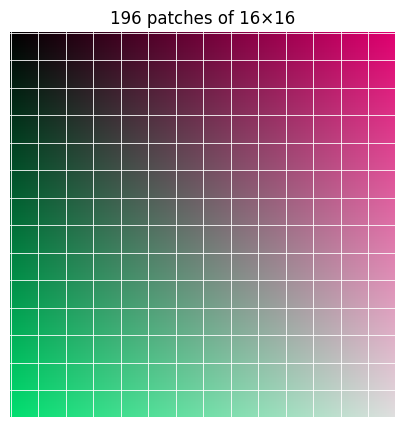

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def load_image(path=None, size=224):
    """Load an image to 224×224 RGB, or make a synthetic one if no path is given."""
    if path:
        img = Image.open(path).convert("RGB").resize((size, size))
        return np.array(img)
    yy, xx = np.mgrid[0:size, 0:size]
    return np.stack([xx % 256, yy % 256, (xx + yy) // 2 % 256], axis=-1).astype(np.uint8)

image = load_image()  # pass a file path, e.g. load_image("/content/my_photo.jpg"), to use a real photo
patch = 16

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image)
for i in range(0, 224, patch):
    ax.axhline(i, color="white", linewidth=0.6)
    ax.axvline(i, color="white", linewidth=0.6)
ax.set_title(f"{(224 // patch) ** 2} patches of {patch}×{patch}")
ax.axis("off")
plt.show()

In [19]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size=224, patch_size=16, in_channels=3, embed_dim=768):
        super().__init__()
        self.projection = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):                      # (B, 3, 224, 224)
        x = self.projection(x)                 # (B, 768, 14, 14): one vector per patch
        return x.flatten(2).transpose(1, 2)    # (B, 196, 768)


class ViTEmbeddings(nn.Module):
    def __init__(self, image_size=224, patch_size=16, in_channels=3, embed_dim=768):
        super().__init__()
        num_patches = (image_size // patch_size) ** 2
        self.patch_embedding = PatchEmbedding(image_size, patch_size, in_channels, embed_dim)
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        self.position_embeddings = nn.Parameter(torch.randn(1, num_patches + 1, embed_dim))

    def forward(self, x):
        x = self.patch_embedding(x)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        return torch.cat([cls, x], dim=1) + self.position_embeddings   # (B, 197, 768)


class EncoderBlock(nn.Module):
    """Same as the GPT-2 block but without the causal mask."""
    def __init__(self, embed_dim=768, num_heads=12, mlp_ratio=4):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
        self.attention = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(embed_dim, embed_dim * mlp_ratio), nn.GELU(),
                                 nn.Linear(embed_dim * mlp_ratio, embed_dim))

    def forward(self, x):
        h = self.norm1(x)
        x = x + self.attention(h, h, h, need_weights=False)[0]
        return x + self.mlp(self.norm2(x))


class VisionTransformer(nn.Module):
    def __init__(self, num_classes=10, depth=12, embed_dim=768, num_heads=12):
        super().__init__()
        self.embeddings = ViTEmbeddings(embed_dim=embed_dim)
        self.encoder = nn.Sequential(*[EncoderBlock(embed_dim, num_heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        x = self.encoder(self.embeddings(x))
        return self.classifier(self.norm(x)[:, 0])   # classify from the [CLS] token


vit = VisionTransformer(num_classes=10)
image_tensor = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0) / 255.0

print("Image:", tuple(image_tensor.shape))
print("After embeddings:", tuple(vit.embeddings(image_tensor).shape))   # (1, 197, 768)
print("Logits:", tuple(vit(image_tensor).shape))                         # (1, 10)
print(f"Parameters: {sum(p.numel() for p in vit.parameters()):,}")       # about 86M, same scale as ViT-Base

Image: (1, 3, 224, 224)
After embeddings: (1, 197, 768)
Logits: (1, 10)
Parameters: 85,806,346


This model is untrained, so its predictions are random. The point is the shapes: **image → 196 patches → 197 tokens with [CLS] → 12 encoder layers → [CLS] → class scores.**

## Key takeaways

1. An LLM call is messages + parameters; `temperature` and `max_tokens` control randomness and cost.
2. Few-shot prompts fix the output **format**; chain of thought helps only on multi-step reasoning.
3. RAG = embed, retrieve top-k, answer only from context. Top-k always returns k results, so filter or rerank weak matches.
4. Evaluate with a fixed test set and LLM-as-judge (faithfulness, relevance), not by eyeballing.
5. Attention = softmax(QKᵀ/√d<sub>k</sub>)V. Causal masking stops GPT from seeing the future; multiple heads capture different relationships; residuals and LayerNorm make deep stacks trainable.
6. Base model → SFT → RLHF is how a text predictor becomes an assistant.
7. ViT is the same transformer applied to image patches, with a [CLS] token for classification.